In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.models import Sequential
from pathlib import Path

In [12]:
import pickle
df = pd.read_csv(r'E:\Portfolio Optimization & Market Trend Predictor repos\data\sp500_stocks_2025.csv')  # Ensure your CSV has 'Date' and 'Close' columns 

# 2. Preprocess and Scale Data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['close']])

# 3. Create Time-Series Sequences (Lookback Window)
# LSTMs require 3D input: [samples, time_steps, features]

look_back = 60
X, y = [], []
for i in range(look_back, len(df)):
    X.append(scaled_data[i - look_back : i, 0])
    y.append(scaled_data[i, 0])
        
X = np.array(X)
y = np.array(y)


# Reshape X to be [samples, time_steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# Split into Train and Test sets (80/20 split)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]
model_path = "E:\\Portfolio Optimization & Market Trend Predictor repos\\models\\lstm_stock_model.pkl"

with open(model_path, "rb") as f:
    model = pickle.load(f)

# 7. Make Predictions & Inverse Scale
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)
y_test_scaled = scaler.inverse_transform(y_test.reshape(-1, 1))

780/780 ━━━━━━━━━━━━━━━━━━━━ 56s 68ms/step


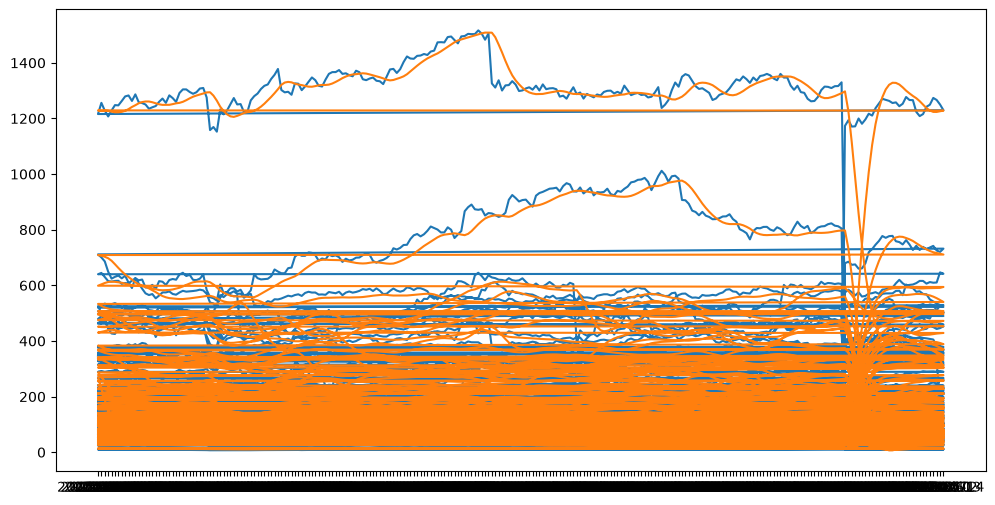

In [59]:
plt.figure(figsize=(12, 6))
plt.plot(df['date'].iloc[-len(y_test) :], y_test_scaled, label='Actual Price')
plt.plot(
    df['date'].iloc[-len(y_test) :], predictions, label='LSTM Predicted Price'
)

In [61]:
import pandas as pd

# 1. Ensure your predictions and actual test prices are 1D arrays (flatten them if needed)
actual_prices_flat = y_test_scaled.flatten()
predicted_prices_flat = predictions.flatten()
test_dates = df['date'].iloc[-len(y_test) :].values

# 2. Create a clean results DataFrame
results_df = pd.DataFrame({
    'Date': test_dates,
    'Actual_Price': actual_prices_flat,
    'Predicted_Price': predicted_prices_flat,
})

# 3. Export to a CSV file
output_filename = 'E:\\Portfolio Optimization & Market Trend Predictor repos\\reports\\stock_predictions_output.csv'
results_df.to_csv(output_filename, index=False)

print(f'Predictions successfully exported to {output_filename}')

Predictions successfully exported to E:\Portfolio Optimization & Market Trend Predictor repos\reports\stock_predictions_output.csv


In [ ]:
df1 = pd.read_csv(r'E:\Portfolio Optimization & Market Trend Predictor repos\reports\stock_predictions_output.csv')

df1.head(1)
plt.plot(df1[df1['Actual_Price']], label='Actual Price')

,Date,Actual_Price,Predicted_Price
0,2025-02-18,347.395599,340.17258


In [94]:
df[(df['symbol']=='AAPL')].count()

date      250
open      250
high      250
low       250
close     250
volume    250
symbol    250
dtype: int64

In [98]:
df['symbol'].unique().size*250

np.int64(125000)

In [101]:
df['symbol'].count()


#plt.savefig("E:/Portfolio Optimization & Market Trend Predictor repos/reports/lstm_stock_prediction.png", dpi=300, bbox_inches="tight")

np.int64(124767)

ValueError: x and y must have same first dimension, but have shapes (7,) and (24942, 1)

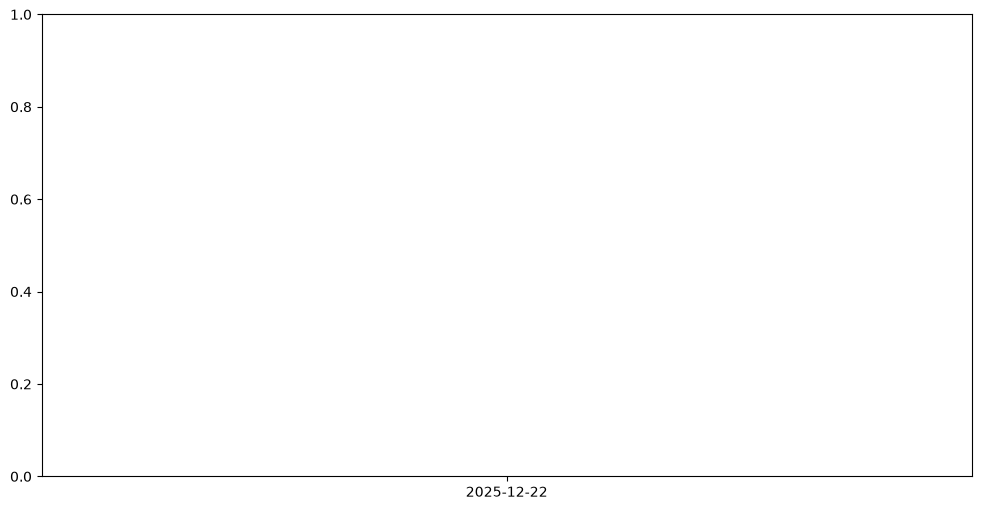

In [41]:
plt.figure(figsize=(12, 6))
plt.plot(df['date'].iloc[-7 :], y_test_scaled, label='Actual Price')
plt.plot(
    df['date'].iloc[-7:], predictions, label='LSTM Predicted Price'
)

In [ ]:
X_all , y_all = [], []  
count = round(df['symbol'].count()/df['symbol'].nunique())
  
for ticker, group in df.groupby('symbol'):
    # Sort just to be safe on chronological order
    group = group.sort_values('date')
    prices = group[['close']].values  # Extract price values
    if len(prices) !=count:
      continue
    # Ensure the company has enough data to fill the lookback window
    if len(prices) > look_back:
      for i in range(look_back, len(prices)):
        X_all.append(prices[i - look_back : i, 0])
        y_all.append(prices[i, 0])

In [114]:
X_all , y_all = [], []  
count = round(df['symbol'].count()/df['symbol'].nunique())
print(count)

250


In [116]:
scaler = MinMaxScaler(feature_range=(0, 1))
df['close'] = scaler.fit_transform(df[['close']])

print(df['close'])


0         0.014618
1         0.014879
2         0.014964
3         0.015078
4         0.015030
            ...   
124762    0.013673
124763    0.013759
124764    0.013730
124765    0.013780
124766    0.013712
Name: close, Length: 124767, dtype: float64


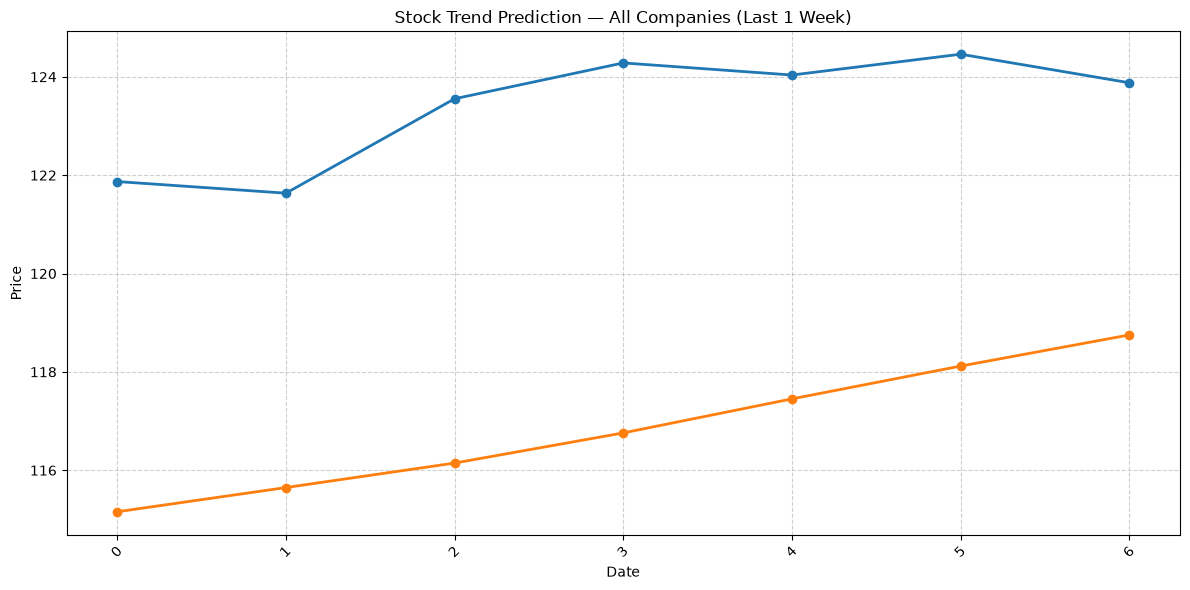

In [58]:


# If y_test_scaled is a 2D array or DataFrame containing all companies:
# Matplotlib automatically loops through columns and plots a line for each!
plt.figure(figsize=(12, 6))
plt.plot(
    y_test_scaled[-7:],
    marker='o',
    linewidth=2,
)
plt.plot(
    predictions[-7:],
    marker='o',
    linewidth=2,
)

plt.title('Stock Trend Prediction — All Companies (Last 1 Week)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45)

# Optional: If you want a legend, you can pass column names or a list of tickers
# plt.legend(['Apple', 'Microsoft', 'Tesla', 'Google'])

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()